<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Order_book_liquidity_state_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload BTCUSDT_Depth_1Hour.csv


Saving BTCUSDT_Depth_1Hour.csv to BTCUSDT_Depth_1Hour.csv

File loaded successfully:
BTCUSDT_Depth_1Hour.csv
Rows    : 35,901
Columns : 45

Detected order-book columns:
Bid price levels : 10
Ask price levels : 10
Bid quantity     : 11
Ask quantity     : 11

Using 10 order-book levels.

LIQUIDITY FEATURE MATRIX
Observations : 7,813
Features     : 15
• Relative_Spread
• Bid_Depth
• Ask_Depth
• Total_Depth
• OBI
• Depth_Ratio
• Depth_Share_Bid
• Bid_Queue_Ratio
• Ask_Queue_Ratio
• Bid_Depth_Concentration
• Ask_Depth_Concentration
• Volatility_20
• Volatility_50
• Depth_Change
• Spread_Change

K SELECTION — SILHOUETTE ANALYSIS


,K,Inertia,Silhouette_Score
0,2,"87,143.64",0.3185
1,3,"79,678.82",0.3291
2,4,"72,928.33",0.2406
3,5,"66,544.55",0.2430
4,6,"60,276.77",0.2482
5,7,"54,678.89",0.2743
6,8,"48,542.67",0.2767



Optimal K             : 3
Best Silhouette Score : 0.3291


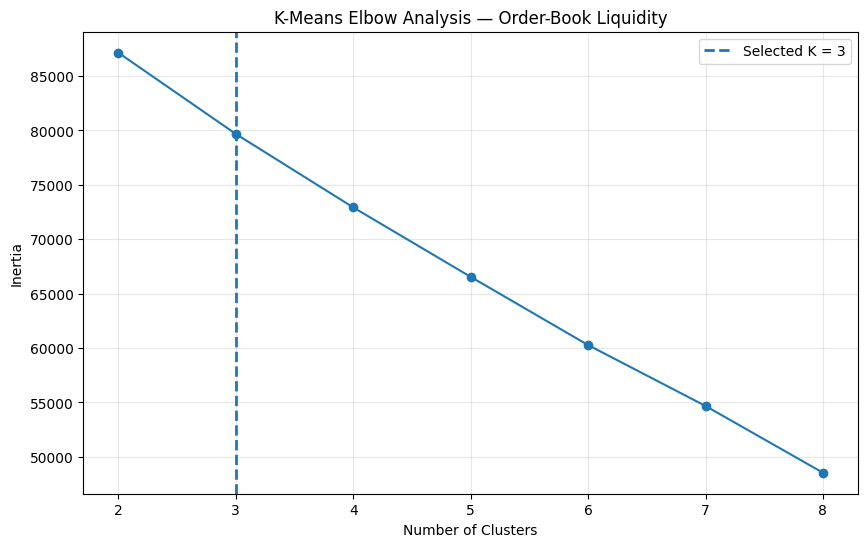

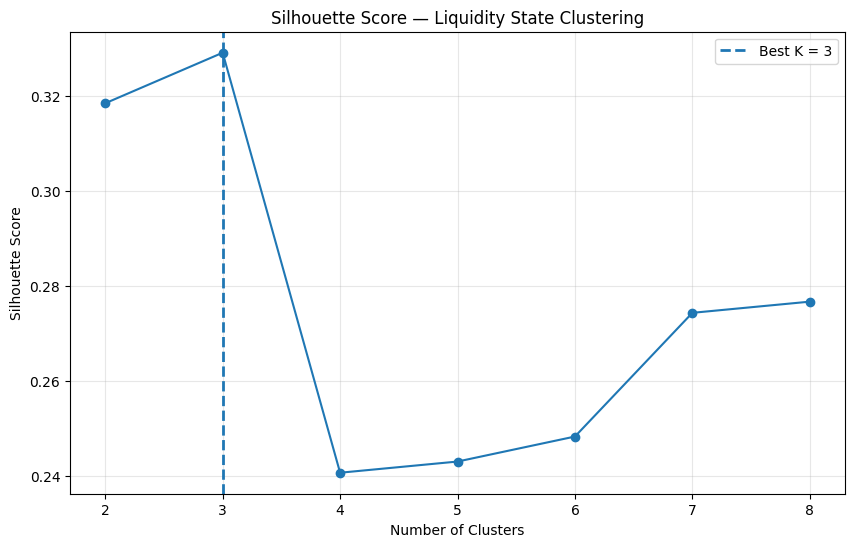


LIQUIDITY CLUSTER PROFILES


,Relative_Spread,Bid_Depth,Ask_Depth,Total_Depth,OBI,Depth_Ratio,Bid_Queue_Ratio,Ask_Queue_Ratio,Volatility_20,Volatility_50,Depth_Change,Spread_Change,Observations,Frequency_%
Cluster,,,,,,,,,,,,,,
0,0.000016,7.736795,2.141784,9.878580,0.555296,283.572455,0.770521,0.313980,0.002189,0.009239,3.901852,35.991585,3717,47.574555
1,0.000017,1.223931,6.805424,8.029355,-0.651939,0.274527,0.331562,0.646621,0.001456,0.011110,10.014885,40.991532,3508,44.899526
2,0.000014,3.398124,5.251957,8.650081,-0.237438,29.196821,0.504689,0.535600,0.094455,0.072212,150.127461,25.682981,588,7.525918



CLUSTER → LIQUIDITY STATE
Cluster 0 → Normal Liquidity
Cluster 1 → Thin Liquidity
Cluster 2 → Deep Liquidity

LIQUIDITY STATE FREQUENCY


,Observations,Frequency_%
Liquidity_State,,
Normal Liquidity,3717,47.57%
Thin Liquidity,3508,44.90%
Deep Liquidity,588,7.53%


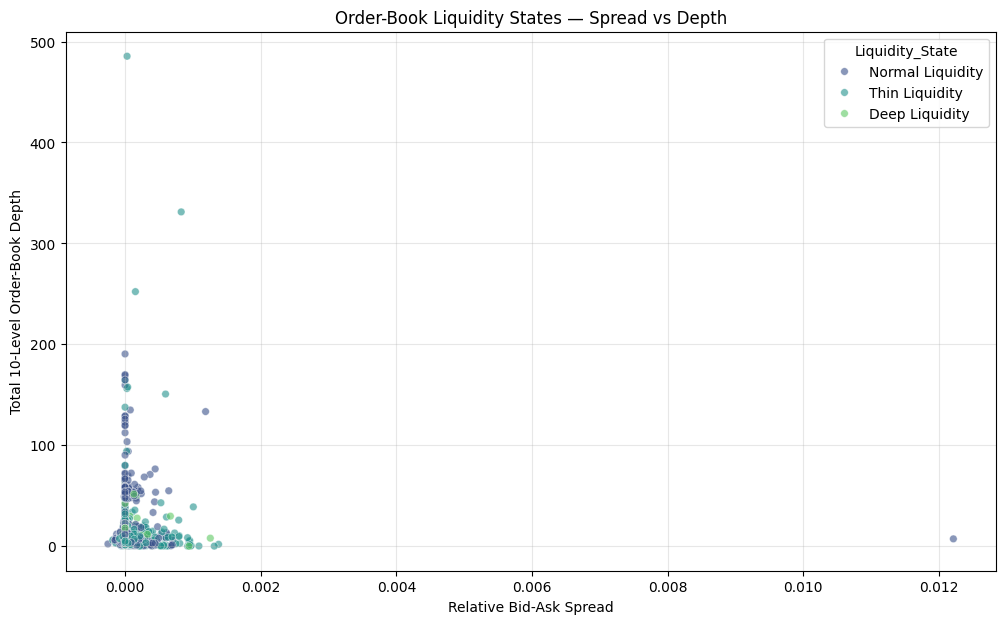

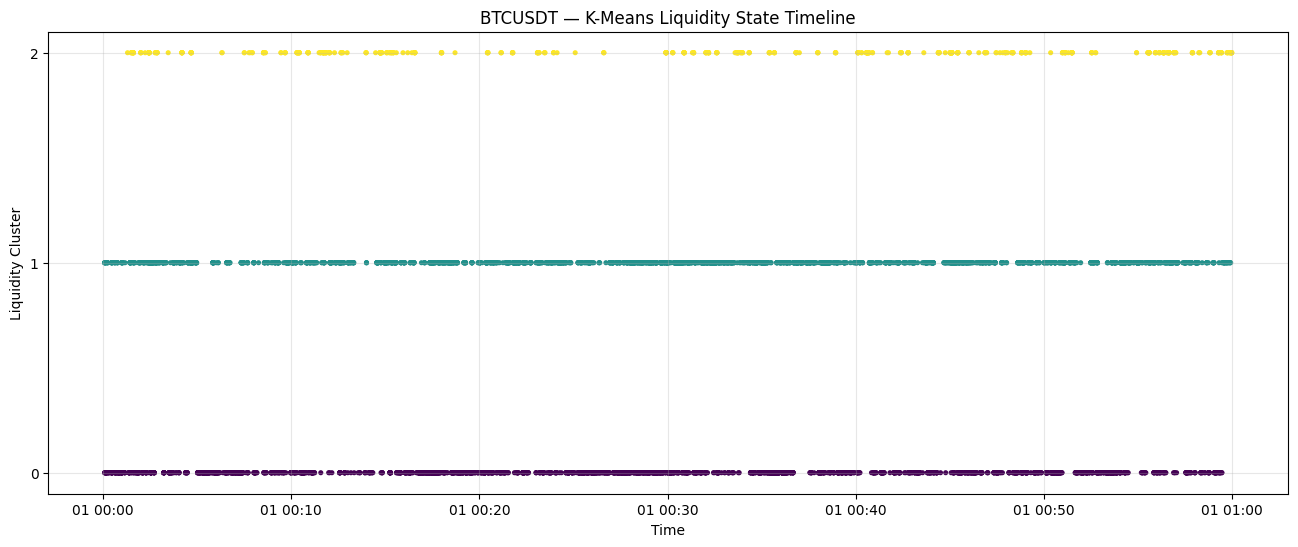

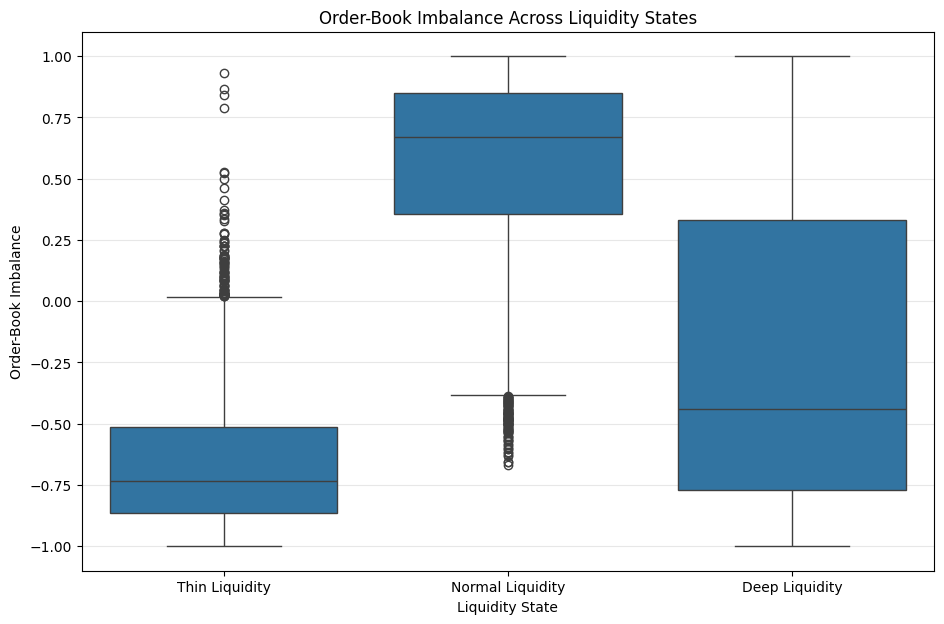

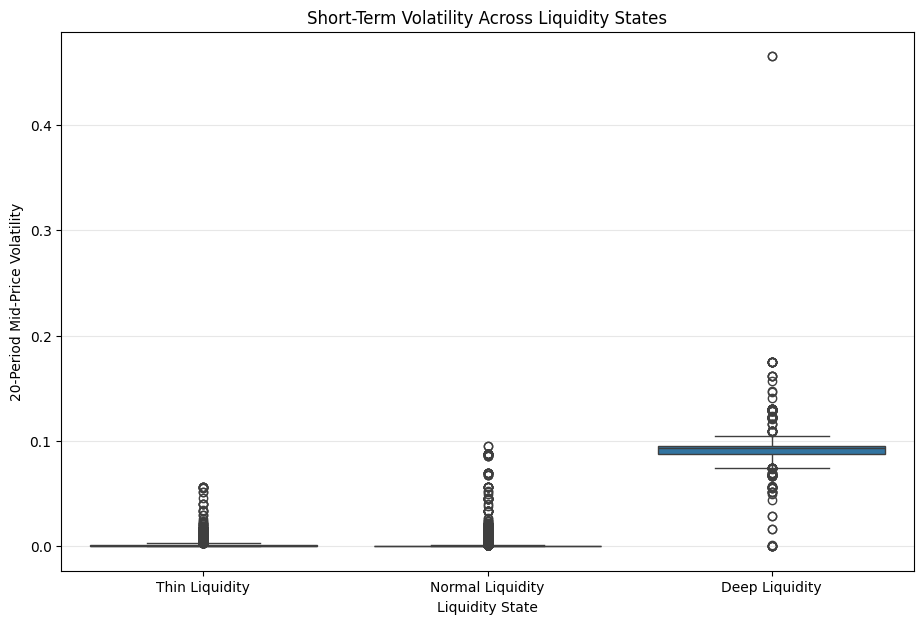


LIQUIDITY STATE TRANSITION MATRIX


Liquidity_State,Deep Liquidity,Normal Liquidity,Thin Liquidity
Liquidity_State,,,
Deep Liquidity,0.7700,0.1022,0.1278
Normal Liquidity,0.0135,0.8741,0.1125
Thin Liquidity,0.0245,0.1163,0.8592


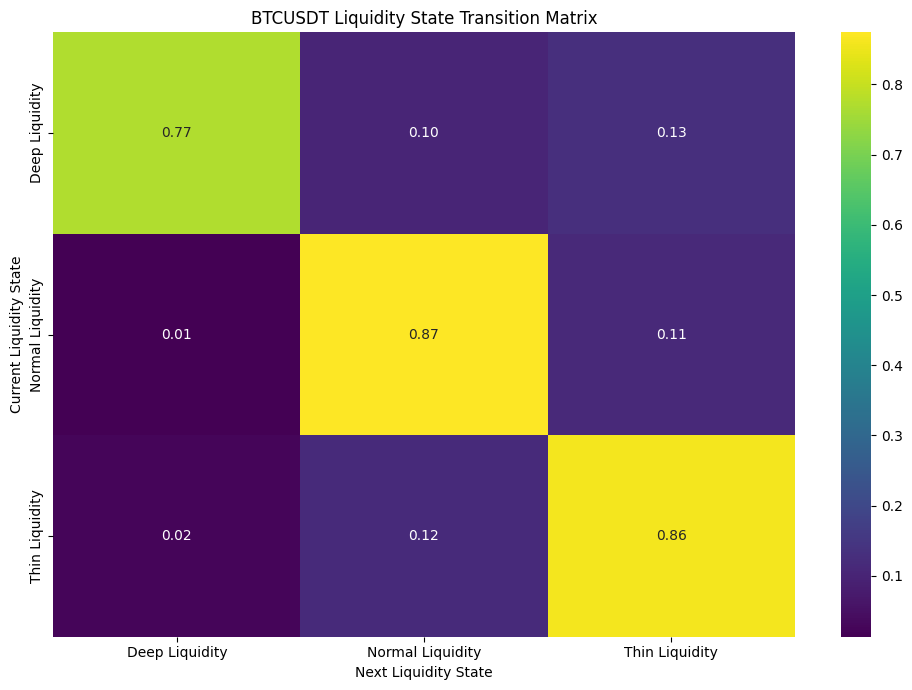


LIQUIDITY STATE DURATION


,Episodes,Average_Duration,Median_Duration,Maximum_Duration
Liquidity_State,,,,
Deep Liquidity,136,4.32,4.0,22
Normal Liquidity,468,7.94,3.0,112
Thin Liquidity,494,7.10,4.0,52



CURRENT ORDER-BOOK LIQUIDITY STATE
Timestamp       : 2024-03-01 00:59:58.465000
Cluster         : 2
Liquidity State  : Deep Liquidity
Relative Spread : 0.000061
Total Depth     : 3.4037
OBI             : -0.8992
20-Period Vol   : 0.067438


NameError: name 'silhouett' is not defined

In [ ]:
# ============================================================
# K-MEANS ORDER-BOOK LIQUIDITY STATE CLUSTERING
# BTCUSDT LEVEL-2 ORDER BOOK
# SILHOUETTE ANALYSIS + K-MEANS
# ============================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ============================================================
# 1. IMPORT / UPLOAD ORDER-BOOK FILE
# ============================================================

print("Upload BTCUSDT_Depth_1Hour.csv")

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[file_name])
)

print("\nFile loaded successfully:")
print(file_name)

print(f"Rows    : {len(df):,}")
print(f"Columns : {len(df.columns)}")

# ============================================================
# 2. IDENTIFY ORDER-BOOK COLUMNS
# ============================================================

columns_lower = {
    col: col.lower().replace(" ", "").replace("_", "")
    for col in df.columns
}

# Timestamp detection
timestamp_candidates = [
    col for col in df.columns
    if any(x in columns_lower[col]
           for x in ["timestamp", "time", "datetime", "date"])
]

if timestamp_candidates:

    timestamp_col = timestamp_candidates[0]

    try:
        df[timestamp_col] = pd.to_datetime(
            df[timestamp_col],
            errors="coerce"
        )

        df = df.dropna(
            subset=[timestamp_col]
        ).sort_values(
            timestamp_col
        )

    except:
        timestamp_col = None

else:
    timestamp_col = None

# ------------------------------------------------------------
# Detect bid/ask price and quantity columns
# ------------------------------------------------------------

bid_price_cols = []
ask_price_cols = []

bid_qty_cols = []
ask_qty_cols = []

for col in df.columns:

    c = columns_lower[col]

    if (
        ("bid" in c) and
        ("price" in c or "px" in c)
    ):
        bid_price_cols.append(col)

    elif (
        ("ask" in c) or ("offer" in c)
    ) and (
        "price" in c or "px" in c
    ):
        ask_price_cols.append(col)

    if (
        ("bid" in c) and
        (
            "qty" in c or
            "quantity" in c or
            "volume" in c or
            "size" in c
        )
    ):
        bid_qty_cols.append(col)

    elif (
        ("ask" in c or "offer" in c) and
        (
            "qty" in c or
            "quantity" in c or
            "volume" in c or
            "size" in c
        )
    ):
        ask_qty_cols.append(col)

# ============================================================
# 3. SORT LEVELS
# ============================================================

def level_number(col):

    import re

    numbers = re.findall(
        r"\d+",
        str(col)
    )

    if numbers:
        return int(numbers[-1])

    return 999


bid_price_cols = sorted(
    bid_price_cols,
    key=level_number
)

ask_price_cols = sorted(
    ask_price_cols,
    key=level_number
)

bid_qty_cols = sorted(
    bid_qty_cols,
    key=level_number
)

ask_qty_cols = sorted(
    ask_qty_cols,
    key=level_number
)

print("\nDetected order-book columns:")
print(f"Bid price levels : {len(bid_price_cols)}")
print(f"Ask price levels : {len(ask_price_cols)}")
print(f"Bid quantity     : {len(bid_qty_cols)}")
print(f"Ask quantity     : {len(ask_qty_cols)}")

# ============================================================
# 4. VALIDATE ORDER BOOK
# ============================================================

if len(bid_price_cols) == 0:
    raise ValueError(
        "No bid-price columns detected."
    )

if len(ask_price_cols) == 0:
    raise ValueError(
        "No ask-price columns detected."
    )

if len(bid_qty_cols) == 0:
    raise ValueError(
        "No bid-quantity columns detected."
    )

if len(ask_qty_cols) == 0:
    raise ValueError(
        "No ask-quantity columns detected."
    )

# Use common number of levels
n_levels = min(
    len(bid_price_cols),
    len(ask_price_cols),
    len(bid_qty_cols),
    len(ask_qty_cols),
    10
)

bid_price_cols = bid_price_cols[:n_levels]
ask_price_cols = ask_price_cols[:n_levels]
bid_qty_cols = bid_qty_cols[:n_levels]
ask_qty_cols = ask_qty_cols[:n_levels]

print(
    f"\nUsing {n_levels} order-book levels."
)

# ============================================================
# 5. CONVERT NUMERIC COLUMNS
# ============================================================

numeric_cols = (
    bid_price_cols +
    ask_price_cols +
    bid_qty_cols +
    ask_qty_cols
)

for col in numeric_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# ============================================================
# 6. BEST BID / ASK
# ============================================================

df["Best_Bid"] = df[
    bid_price_cols[0]
]

df["Best_Ask"] = df[
    ask_price_cols[0]
]

df["Best_Bid_Qty"] = df[
    bid_qty_cols[0]
]

df["Best_Ask_Qty"] = df[
    ask_qty_cols[0]
]

# Mid-price
df["Mid_Price"] = (
    df["Best_Bid"] +
    df["Best_Ask"]
) / 2

# ============================================================
# 7. SPREAD FEATURES
# ============================================================

df["Spread"] = (
    df["Best_Ask"] -
    df["Best_Bid"]
)

df["Relative_Spread"] = (
    df["Spread"] /
    df["Mid_Price"]
)

# ============================================================
# 8. MULTI-LEVEL DEPTH
# ============================================================

df["Bid_Depth"] = df[
    bid_qty_cols
].sum(axis=1)

df["Ask_Depth"] = df[
    ask_qty_cols
].sum(axis=1)

df["Total_Depth"] = (
    df["Bid_Depth"] +
    df["Ask_Depth"]
)

# ============================================================
# 9. ORDER-BOOK IMBALANCE
# ============================================================

df["OBI"] = (
    (df["Bid_Depth"] -
     df["Ask_Depth"]) /
    (df["Bid_Depth"] +
     df["Ask_Depth"])
)

# ============================================================
# 10. BID / ASK DEPTH RATIO
# ============================================================

df["Depth_Ratio"] = (
    df["Bid_Depth"] /
    df["Ask_Depth"].replace(0, np.nan)
)

df["Depth_Share_Bid"] = (
    df["Bid_Depth"] /
    df["Total_Depth"].replace(0, np.nan)
)

# ============================================================
# 11. QUEUE RATIOS
# ============================================================

df["Bid_Queue_Ratio"] = (
    df["Best_Bid_Qty"] /
    df["Bid_Depth"].replace(0, np.nan)
)

df["Ask_Queue_Ratio"] = (
    df["Best_Ask_Qty"] /
    df["Ask_Depth"].replace(0, np.nan)
)

# ============================================================
# 12. DEPTH CONCENTRATION
# ============================================================

df["Bid_Depth_Concentration"] = (
    df["Best_Bid_Qty"] /
    df["Bid_Depth"].replace(0, np.nan)
)

df["Ask_Depth_Concentration"] = (
    df["Best_Ask_Qty"] /
    df["Ask_Depth"].replace(0, np.nan)
)

# ============================================================
# 13. SHORT-TERM PRICE VOLATILITY
# ============================================================

df["Mid_Return"] = (
    df["Mid_Price"].pct_change()
)

df["Volatility_20"] = (
    df["Mid_Return"]
    .rolling(20)
    .std()
)

df["Volatility_50"] = (
    df["Mid_Return"]
    .rolling(50)
    .std()
)

# ============================================================
# 14. SHORT-TERM LIQUIDITY CHANGE
# ============================================================

df["Depth_Change"] = (
    df["Total_Depth"].pct_change()
)

df["Spread_Change"] = (
    df["Relative_Spread"].pct_change()
)

# ============================================================
# 15. CLEAN DATA
# ============================================================

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

df = df.dropna()

# ============================================================
# 16. LIQUIDITY FEATURE MATRIX
# ============================================================

features = [

    "Relative_Spread",

    "Bid_Depth",

    "Ask_Depth",

    "Total_Depth",

    "OBI",

    "Depth_Ratio",

    "Depth_Share_Bid",

    "Bid_Queue_Ratio",

    "Ask_Queue_Ratio",

    "Bid_Depth_Concentration",

    "Ask_Depth_Concentration",

    "Volatility_20",

    "Volatility_50",

    "Depth_Change",

    "Spread_Change"
]

X = df[features].copy()

# ------------------------------------------------------------
# Log-transform highly skewed positive variables
# ------------------------------------------------------------

for col in [
    "Bid_Depth",
    "Ask_Depth",
    "Total_Depth"
]:

    X[col] = np.log1p(
        X[col].clip(lower=0)
    )

# ============================================================
# 17. STANDARDIZATION
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\n" + "=" * 70)
print("LIQUIDITY FEATURE MATRIX")
print("=" * 70)

print(
    f"Observations : {len(X):,}"
)

print(
    f"Features     : {len(features)}"
)

for feature in features:
    print("•", feature)

# ============================================================
# 18. SILHOUETTE ANALYSIS
# ============================================================

k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    labels = model.fit_predict(
        X_scaled
    )

    inertias.append(
        model.inertia_
    )

    silhouette_scores.append(
        silhouette_score(
            X_scaled,
            labels
        )
    )

evaluation = pd.DataFrame({

    "K": list(k_values),

    "Inertia": inertias,

    "Silhouette_Score":
        silhouette_scores
})

print("\n" + "=" * 70)
print("K SELECTION — SILHOUETTE ANALYSIS")
print("=" * 70)

display(
    evaluation.style.format({

        "Inertia": "{:,.2f}",

        "Silhouette_Score":
            "{:.4f}"
    })
)

# ============================================================
# 19. SELECT OPTIMAL K
# ============================================================

best_k = int(
    evaluation.loc[
        evaluation[
            "Silhouette_Score"
        ].idxmax(),
        "K"
    ]
)

best_score = evaluation.loc[
    evaluation["K"] == best_k,
    "Silhouette_Score"
].iloc[0]

print(
    f"\nOptimal K             : {best_k}"
)

print(
    f"Best Silhouette Score : "
    f"{best_score:.4f}"
)

# ============================================================
# 20. ELBOW PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    evaluation["K"],
    evaluation["Inertia"],
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    linewidth=2,
    label=f"Selected K = {best_k}"
)

plt.title(
    "K-Means Elbow Analysis — Order-Book Liquidity"
)

plt.xlabel("Number of Clusters")

plt.ylabel("Inertia")

plt.xticks(
    list(k_values)
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

# ============================================================
# 21. SILHOUETTE SCORE PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    evaluation["K"],
    evaluation["Silhouette_Score"],
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    linewidth=2,
    label=f"Best K = {best_k}"
)

plt.title(
    "Silhouette Score — Liquidity State Clustering"
)

plt.xlabel(
    "Number of Clusters"
)

plt.ylabel(
    "Silhouette Score"
)

plt.xticks(
    list(k_values)
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

# ============================================================
# 22. FINAL K-MEANS MODEL
# ============================================================

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=100
)

df["Cluster"] = (
    final_model.fit_predict(
        X_scaled
    )
)

# ============================================================
# 23. LIQUIDITY CLUSTER PROFILE
# ============================================================

profile_features = [

    "Relative_Spread",
    "Bid_Depth",
    "Ask_Depth",
    "Total_Depth",
    "OBI",
    "Depth_Ratio",
    "Bid_Queue_Ratio",
    "Ask_Queue_Ratio",
    "Volatility_20",
    "Volatility_50",
    "Depth_Change",
    "Spread_Change"
]

cluster_profile = df.groupby(
    "Cluster"
)[profile_features].mean()

cluster_profile["Observations"] = (
    df["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_profile["Frequency_%"] = (
    cluster_profile["Observations"] /
    len(df) * 100
)

print("\n" + "=" * 70)
print("LIQUIDITY CLUSTER PROFILES")
print("=" * 70)

display(
    cluster_profile.round(6)
)

# ============================================================
# 24. LIQUIDITY STATE INTERPRETATION
# ============================================================

# Higher total depth + lower spread = deeper/more liquid
# Lower depth + higher spread = thinner/less liquid

liquidity_score = (
    cluster_profile["Total_Depth"].rank(
        ascending=True
    )
    -
    cluster_profile["Relative_Spread"].rank(
        ascending=True
    )
)

# Sort based on liquidity characteristics
liquidity_order = (
    cluster_profile
    .assign(Liquidity_Score=liquidity_score)
    ["Liquidity_Score"]
    .sort_values()
    .index
    .tolist()
)

state_names = {}

if len(liquidity_order) == 2:

    state_names = {
        liquidity_order[0]: "Thin Liquidity",
        liquidity_order[1]: "Deep Liquidity"
    }

elif len(liquidity_order) == 3:

    state_names = {
        liquidity_order[0]: "Thin Liquidity",
        liquidity_order[1]: "Normal Liquidity",
        liquidity_order[2]: "Deep Liquidity"
    }

else:

    for i, cluster in enumerate(
        liquidity_order
    ):

        if i == 0:
            name = "Very Thin Liquidity"

        elif i == len(liquidity_order) - 1:
            name = "Very Deep Liquidity"

        else:
            name = f"Liquidity State {i+1}"

        state_names[cluster] = name

df["Liquidity_State"] = (
    df["Cluster"].map(state_names)
)

print("\n" + "=" * 70)
print("CLUSTER → LIQUIDITY STATE")
print("=" * 70)

for cluster in sorted(state_names):

    print(
        f"Cluster {cluster} → "
        f"{state_names[cluster]}"
    )

# ============================================================
# 25. LIQUIDITY STATE FREQUENCY
# ============================================================

state_frequency = (
    df["Liquidity_State"]
    .value_counts()
    .to_frame("Observations")
)

state_frequency["Frequency_%"] = (
    state_frequency["Observations"] /
    len(df) * 100
)

print("\nLIQUIDITY STATE FREQUENCY")

display(
    state_frequency.style.format({
        "Frequency_%": "{:.2f}%"
    })
)

# ============================================================
# 26. SPREAD VS DEPTH
# ============================================================

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df.sample(
        min(15000, len(df)),
        random_state=42
    ),
    x="Relative_Spread",
    y="Total_Depth",
    hue="Liquidity_State",
    palette="viridis",
    alpha=0.6,
    s=30
)

plt.title(
    "Order-Book Liquidity States — Spread vs Depth"
)

plt.xlabel(
    "Relative Bid-Ask Spread"
)

plt.ylabel(
    "Total 10-Level Order-Book Depth"
)

plt.grid(alpha=0.3)

plt.show()

# ============================================================
# 27. LIQUIDITY STATE TIMELINE
# ============================================================

timeline_sample = df.copy()

# If timestamp exists, use it
if timestamp_col is not None:

    timeline_x = timeline_sample[
        timestamp_col
    ]

else:

    timeline_x = np.arange(
        len(timeline_sample)
    )

plt.figure(figsize=(16, 6))

plt.scatter(
    timeline_x,
    timeline_sample["Cluster"],
    c=timeline_sample["Cluster"],
    cmap="viridis",
    s=7
)

plt.title(
    "BTCUSDT — K-Means Liquidity State Timeline"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "Liquidity Cluster"
)

plt.yticks(
    sorted(
        df["Cluster"].unique()
    )
)

plt.grid(alpha=0.3)

plt.show()

# ============================================================
# 28. ORDER-BOOK IMBALANCE BY LIQUIDITY STATE
# ============================================================

plt.figure(figsize=(11, 7))

sns.boxplot(
    data=df,
    x="Liquidity_State",
    y="OBI"
)

plt.title(
    "Order-Book Imbalance Across Liquidity States"
)

plt.xlabel(
    "Liquidity State"
)

plt.ylabel(
    "Order-Book Imbalance"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

# ============================================================
# 29. VOLATILITY BY LIQUIDITY STATE
# ============================================================

plt.figure(figsize=(11, 7))

sns.boxplot(
    data=df,
    x="Liquidity_State",
    y="Volatility_20"
)

plt.title(
    "Short-Term Volatility Across Liquidity States"
)

plt.xlabel(
    "Liquidity State"
)

plt.ylabel(
    "20-Period Mid-Price Volatility"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

# ============================================================
# 30. LIQUIDITY STATE TRANSITION MATRIX
# ============================================================

transition_matrix = pd.crosstab(
    df["Liquidity_State"],
    df["Liquidity_State"].shift(-1),
    normalize="index"
)

print("\n" + "=" * 70)
print("LIQUIDITY STATE TRANSITION MATRIX")
print("=" * 70)

display(
    transition_matrix.round(4)
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    transition_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis"
)

plt.title(
    "BTCUSDT Liquidity State Transition Matrix"
)

plt.xlabel(
    "Next Liquidity State"
)

plt.ylabel(
    "Current Liquidity State"
)

plt.tight_layout()

plt.show()

# ============================================================
# 31. LIQUIDITY STATE DURATION
# ============================================================

regime_change = (
    df["Liquidity_State"] !=
    df["Liquidity_State"].shift(1)
)

episode_id = regime_change.cumsum()

duration_data = pd.DataFrame({

    "Liquidity_State":
        df["Liquidity_State"].values,

    "Episode":
        episode_id.values
})

durations = (
    duration_data
    .groupby(
        ["Liquidity_State", "Episode"]
    )
    .size()
    .rename("Duration")
    .reset_index()
)

duration_summary = (
    durations
    .groupby("Liquidity_State")[
        "Duration"
    ]
    .agg(
        Episodes="count",
        Average_Duration="mean",
        Median_Duration="median",
        Maximum_Duration="max"
    )
)

print("\nLIQUIDITY STATE DURATION")

display(
    duration_summary.round(2)
)

# ============================================================
# 32. CURRENT LIQUIDITY STATE
# ============================================================

latest = df.iloc[-1]

print("\n" + "=" * 70)
print("CURRENT ORDER-BOOK LIQUIDITY STATE")
print("=" * 70)

if timestamp_col is not None:
    print(
        f"Timestamp       : "
        f"{latest[timestamp_col]}"
    )

print(
    f"Cluster         : "
    f"{int(latest['Cluster'])}"
)

print(
    f"Liquidity State  : "
    f"{latest['Liquidity_State']}"
)

print(
    f"Relative Spread : "
    f"{latest['Relative_Spread']:.6f}"
)

print(
    f"Total Depth     : "
    f"{latest['Total_Depth']:.4f}"
)

print(
    f"OBI             : "
    f"{latest['OBI']:.4f}"
)

print(
    f"20-Period Vol   : "
    f"{latest['Volatility_20']:.6f}"
)

# ============================================================
# 33. FINAL SILHOUETTE VALIDATION
# ============================================================

final_silhouette = silhouett

In [ ]:
# ============================================================
# FINAL SILHOUETTE VALIDATION
# ============================================================

from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("=" * 70)
print("FINAL MODEL VALIDATION")
print("=" * 70)

print(f"Optimal K              : {best_k}")
print(f"Final Silhouette Score : {final_silhouette:.4f}")

# Save final results
df.to_csv(
    "BTCUSDT_KMeans_Liquidity_States.csv",
    index=False
)

evaluation.to_csv(
    "KMeans_Liquidity_Silhouette_Evaluation.csv",
    index=False
)

cluster_profile.to_csv(
    "KMeans_Liquidity_Cluster_Profiles.csv"
)

state_frequency.to_csv(
    "KMeans_Liquidity_State_Frequency.csv"
)

transition_matrix.to_csv(
    "KMeans_Liquidity_Transition_Matrix.csv"
)

duration_summary.to_csv(
    "KMeans_Liquidity_State_Duration.csv"
)

print("\nAll final files saved successfully.")

FINAL MODEL VALIDATION
Optimal K              : 3
Final Silhouette Score : 0.3292

All final files saved successfully.
